# 01. Data Engineering & BIO Tagging Pipeline
## SemEval-2021 Task 5: Toxic Spans Detection

### 1. Problem Formulation & Motivation
Unlike document-level or comment-level toxicity classification, **Toxic Spans Detection (SemEval-2021 Task 5)** frames toxicity localization as a fine-grained **Sequence Labeling** problem. Given an input sequence of characters $C = (c_1, c_2, \dots, c_L)$, the ground truth annotation provides a subset of character indices $S \subseteq \{0, 1, \dots, L-1\}$ corresponding to toxic expressions.

To make this tractable for sequence labeling architectures (such as Hidden Markov Models, Linear-Chain Conditional Random Fields, and Bidirectional LSTM-CRFs), we transform character-level index sets $S$ into word/token-level **BIO (Beginning-Inside-Outside)** tags:
- **`B-TOXIC`**: Marks the initial token of a contiguous toxic span.
- **`I-TOXIC`**: Marks subsequent contiguous tokens inside the same toxic span.
- **`O`**: Marks non-toxic (outside) tokens.

This notebook performs:
1. Automated fetching of the official SemEval-2021 Task 5 training and test sets (with local file fallback).
2. Rigorous parsing of character-level offsets using `ast.literal_eval`.
3. Offset-aware tokenization (`\w+|[^\w\s]`) that preserves exact start/end character coordinates $(s_i, e_i)$ for each token $w_i$.
4. Contiguous character-interval reconstruction to accurately distinguish adjacent vs. multi-word toxic spans (`B-TOXIC` vs. `I-TOXIC`).
5. Exploratory Data Analysis (EDA) and serialization of the BIO-tagged datasets to CSV.

In [2]:
import os
import re
import ast
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seeds and plotting style for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

### 2. Dataset Acquisition & Offset Parsing
We fetch `tsd_train.csv` and `tsd_test.csv` directly from the official SemEval-2021 repository URLs. Each row contains:
- `spans`: A stringified Python list of character indices (e.g., `"[8, 9, 10, 11, 12]"`).
- `text`: The raw user comment string.

We use `ast.literal_eval` to safely parse the stringified list into native Python lists of integers.

In [3]:
TRAIN_URL = "https://raw.githubusercontent.com/ipavlopoulos/toxic_spans/master/SemEval2021/data/tsd_train.csv"
TEST_URL = "https://raw.githubusercontent.com/ipavlopoulos/toxic_spans/master/SemEval2021/data/tsd_test.csv"

TRAIN_RAW_PATH = "tsd_train.csv"
TEST_RAW_PATH = "tsd_test.csv"

def download_if_missing(url: str, local_path: str):
    if not os.path.exists(local_path):
        print(f"Downloading {local_path} from {url}...")
        urllib.request.urlretrieve(url, local_path)
        print(f"Saved {local_path} ({os.path.getsize(local_path):,} bytes).")
    else:
        print(f"Found existing dataset: {local_path} ({os.path.getsize(local_path):,} bytes).")

download_if_missing(TRAIN_URL, TRAIN_RAW_PATH)
download_if_missing(TEST_URL, TEST_RAW_PATH)

df_train = pd.read_csv(TRAIN_RAW_PATH)
df_test = pd.read_csv(TEST_RAW_PATH)

def parse_char_spans(span_str) -> list:
    """Safely parse stringified list of character offsets using ast.literal_eval."""
    if pd.isna(span_str) or not str(span_str).strip():
        return []
    try:
        parsed = ast.literal_eval(str(span_str))
        return sorted(list(set(int(i) for i in parsed))) if isinstance(parsed, (list, tuple, set)) else []
    except (ValueError, SyntaxError):
        return []

df_train["char_offsets"] = df_train["spans"].apply(parse_char_spans)
df_test["char_offsets"] = df_test["spans"].apply(parse_char_spans)

print(f"Train samples: {len(df_train):,} | Test samples: {len(df_test):,}")
display(df_train.head(3))

Found existing dataset: tsd_train.csv (2,281,497 bytes).
Found existing dataset: tsd_test.csv (445,951 bytes).
Train samples: 7,939 | Test samples: 2,000


,spans,text,char_offsets
0,"[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,...",Another violent and aggressive immigrant killi...,"[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,..."
1,"[33, 34, 35, 36, 37, 38, 39]","I am 56 years old, I am not your fucking junio...","[33, 34, 35, 36, 37, 38, 39]"
2,"[0, 1, 2, 3]","Damn, a whole family. Sad indeed.","[0, 1, 2, 3]"


### 3. Character-to-BIO Sequence Alignment Algorithm
To convert character offsets $S$ into BIO tags without losing span boundary fidelity:
1. **Contiguous Character Interval Extraction**: Given sorted character indices $S$, we group consecutive indices (allowing whitespace gaps of 1 character within the same annotated phrase if both sides are marked, or strictly contiguous character runs) into intervals $[a_k, b_k]$. Specifically, in SemEval-2021 Task 5, annotators highlighted contiguous character blocks (including internal spaces within multi-word expressions). Thus, a contiguous run of indices in $S$ forms a single semantic span $[a_k, b_k]$.
2. **Offset-Preserving Tokenization**: Using regex `re.finditer(r"\w+|[^\w\s]", text)`, we extract each token $w_i$ along with its exact character span $[s_i, e_i)$.
3. **BIO Assignment**:
   - A token $w_i$ with span $[s_i, e_i)$ is toxic if at least half of its characters (or $\ge 1$ character) fall inside $S$.
   - If $w_i$ is toxic and belongs to the same contiguous character interval $[a_k, b_k]$ as the immediately preceding toxic token $w_{i-1}$ (or directly follows a `B-TOXIC`/`I-TOXIC` token when separated only by whitespace), it receives **`I-TOXIC`**.
   - Otherwise, if $w_i$ is toxic, it initiates a new span and receives **`B-TOXIC`**.
   - Non-toxic tokens receive **`O`**.

In [4]:
TOKEN_PATTERN = re.compile(r"\w+|[^\w\s]")

def char_offsets_to_intervals(char_offsets: list) -> list:
    """Convert sorted character indices into contiguous (start, end_inclusive) intervals."""
    if not char_offsets:
        return []
    offsets = sorted(set(char_offsets))
    intervals = []
    start = offsets[0]
    prev = offsets[0]
    for idx in offsets[1:]:
        if idx == prev + 1:
            prev = idx
        else:
            intervals.append((start, prev))
            start = idx
            prev = idx
    intervals.append((start, prev))
    return intervals

def text_and_offsets_to_bio(text: str, char_offsets: list):
    """
    Tokenize text with character offsets and assign BIO tags ('O', 'B-TOXIC', 'I-TOXIC').
    Returns:
        tokens (List[str]): Word/punctuation tokens.
        bio_tags (List[str]): Corresponding BIO labels.
        token_spans (List[Tuple[int, int]]): Character (start, end) for each token.
        entity_spans (List[Tuple[str, int, int]]): Exact token-level entity spans ('TOXIC', tok_start, tok_end_inclusive).
    """
    if not isinstance(text, str) or not text.strip():
        return [], [], [], []
    
    char_set = set(char_offsets)
    intervals = char_offsets_to_intervals(char_offsets)
    
    # Map each toxic character index to its contiguous interval ID
    char_to_interval_id = {}
    for interval_id, (iv_start, iv_end) in enumerate(intervals):
        for c_idx in range(iv_start, iv_end + 1):
            char_to_interval_id[c_idx] = interval_id

    tokens = []
    bio_tags = []
    token_spans = []
    prev_interval_id = None
    prev_was_toxic = False

    for match in TOKEN_PATTERN.finditer(text):
        tok_text = match.group(0)
        s_idx, e_idx = match.start(), match.end()
        
        # Overlap between token character indices and ground-truth toxic character set
        overlap_chars = [c for c in range(s_idx, e_idx) if c in char_set]
        
        # A token is considered toxic if >= 50% of its characters are inside the toxic character set
        if len(overlap_chars) > 0 and (len(overlap_chars) / (e_idx - s_idx)) >= 0.5:
            curr_interval_id = char_to_interval_id[overlap_chars[0]]
            if prev_was_toxic and curr_interval_id == prev_interval_id:
                tag = "I-TOXIC"
            else:
                tag = "B-TOXIC"
            prev_was_toxic = True
            prev_interval_id = curr_interval_id
        else:
            tag = "O"
            prev_was_toxic = False
            prev_interval_id = None

        tokens.append(tok_text)
        bio_tags.append(tag)
        token_spans.append((s_idx, e_idx))

    # Extract exact token-level entity spans from BIO tags for verification
    entity_spans = bio_tags_to_entity_spans(bio_tags)
    return tokens, bio_tags, token_spans, entity_spans

def bio_tags_to_entity_spans(bio_tags: list) -> list:
    """
    Convert a sequence of BIO tags into a list of exact entity spans:
    [('TOXIC', start_token_idx, end_token_idx_inclusive), ...]
    """
    spans = []
    start_idx = None
    for idx, tag in enumerate(bio_tags):
        if tag == "B-TOXIC":
            if start_idx is not None:
                spans.append(("TOXIC", start_idx, idx - 1))
            start_idx = idx
        elif tag == "I-TOXIC":
            if start_idx is None:
                # Handle malformed I-TOXIC without preceding B-TOXIC as starting a new span
                start_idx = idx
        else:  # 'O'
            if start_idx is not None:
                spans.append(("TOXIC", start_idx, idx - 1))
                start_idx = None
    if start_idx is not None:
        spans.append(("TOXIC", start_idx, len(bio_tags) - 1))
    return spans

### 4. Applying the BIO Pipeline & Qualitative Verification
Let us apply `text_and_offsets_to_bio` across both training and test splits and inspect sample conversions to verify that character offsets align cleanly with `B-TOXIC` and `I-TOXIC` tags.

In [5]:
def process_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    records = []
    for idx, row in df.iterrows():
        text = str(row["text"]) if not pd.isna(row["text"]) else ""
        char_offsets = row["char_offsets"]
        tokens, bio_tags, token_spans, entity_spans = text_and_offsets_to_bio(text, char_offsets)
        records.append({
            "id": idx,
            "text": text,
            "spans": str(char_offsets),
            "tokens": str(tokens),
            "bio_tags": str(bio_tags),
            "token_spans": str(token_spans),
            "entity_spans": str(entity_spans),
            "num_tokens": len(tokens),
            "num_toxic_tokens": sum(1 for t in bio_tags if t != "O"),
            "num_toxic_spans": len(entity_spans)
        })
    return pd.DataFrame(records)

bio_train_df = process_dataframe(df_train)
bio_test_df = process_dataframe(df_test)

# Display qualitative verification on first 3 training examples
for i in range(3):
    row = bio_train_df.iloc[i]
    toks = ast.literal_eval(row["tokens"])
    tags = ast.literal_eval(row["bio_tags"])
    tagged_pairs = [f"{w}[{t}]" if t != "O" else w for w, t in zip(toks, tags)]
    print(f"=== Sample {i} ===")
    print("Raw Text      :", row["text"])
    print("BIO Annotated :", " ".join(tagged_pairs))
    print("Entity Spans  :", row["entity_spans"])
    print()

=== Sample 0 ===
Raw Text      : Another violent and aggressive immigrant killing a innocent and intelligent US Citizen.... Sarcasm
BIO Annotated : Another violent[B-TOXIC] and[I-TOXIC] aggressive[I-TOXIC] immigrant[I-TOXIC] killing a innocent and intelligent US Citizen . . . . Sarcasm
Entity Spans  : [('TOXIC', 1, 4)]

=== Sample 1 ===
Raw Text      : I am 56 years old, I am not your fucking junior pal. What you are saying makes no sense. I don't know what you are basing this on. The cheap black market crap is still coming up from Mexican nationals, and the good stuff from BC and Humbolt.  The I5 corridor is still just as busy, and they are still making a ton of money. Nothing has really changed except that the legal market has made it easy for anyone of legal age to buy it.  And the legal market is controlled by corporate growers with million dollar facilities, or a co-op of smaller growers. The Federal government "war on drugs" really has no impact on the legal market in Oregon. I d

### 5. Exploratory Data Analysis (EDA) & Tag Statistics
We analyze the structural properties of our BIO-tagged corpus:
1. **Token Label Distribution**: Proportion of `O`, `B-TOXIC`, and `I-TOXIC` tags. Notice the severe class imbalance typical of span detection tasks, demonstrating why token-level accuracy is misleading and **Exact Span Match F1** is mandatory.
2. **Sequence Length & Span Length Distributions**: Helps inform padding/truncation thresholds and transition priors for our sequence models.

=== BIO Label Distribution Across Splits ===


,Train Count,Train %,Test Count,Test %
O,326184,92.629331,77946,96.850188
B-TOXIC,10295,2.923561,1850,2.298679
I-TOXIC,15660,4.447108,685,0.851133


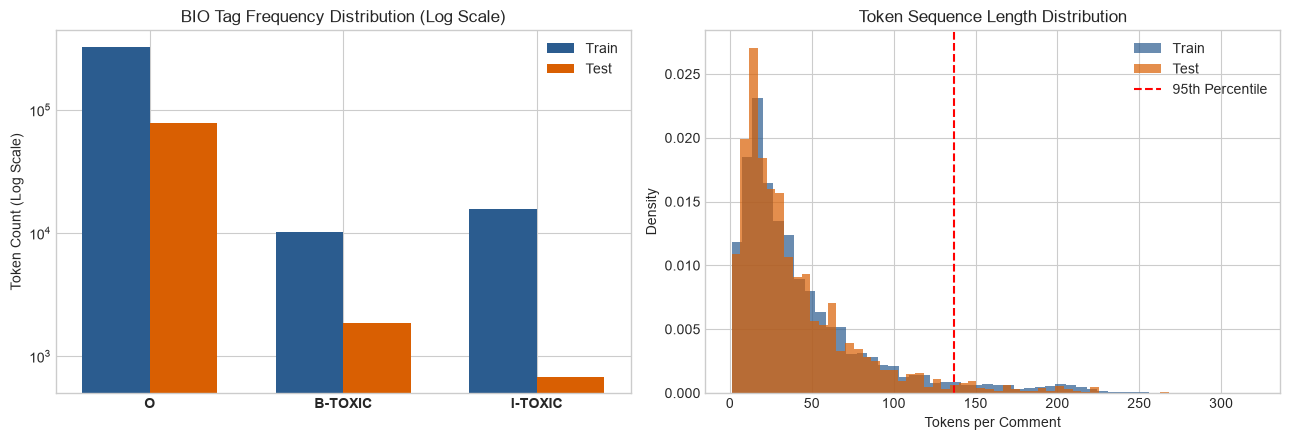

In [9]:
from collections import Counter

train_all_tags = [tag for tags_str in bio_train_df["bio_tags"] for tag in ast.literal_eval(tags_str)]
test_all_tags = [tag for tags_str in bio_test_df["bio_tags"] for tag in ast.literal_eval(tags_str)]

train_tag_counts = Counter(train_all_tags)
test_tag_counts = Counter(test_all_tags)

stats_df = pd.DataFrame({
    "Train Count": train_tag_counts,
    "Train %": {k: v / len(train_all_tags) * 100 for k, v in train_tag_counts.items()},
    "Test Count": test_tag_counts,
    "Test %": {k: v / len(test_all_tags) * 100 for k, v in test_tag_counts.items()},
}).loc[["O", "B-TOXIC", "I-TOXIC"]]

print("=== BIO Label Distribution Across Splits ===")
display(stats_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: BIO Tag Distribution (Log scale to see B-TOXIC and I-TOXIC clearly)
x_labels = ["O", "B-TOXIC", "I-TOXIC"]
x = np.arange(len(x_labels))
width = 0.35
axes[0].bar(x - width/2, [train_tag_counts[k] for k in x_labels], width, label="Train", color="#2b5c8f")
axes[0].bar(x + width/2, [test_tag_counts[k] for k in x_labels], width, label="Test", color="#d95f02")
axes[0].set_yscale("log")
axes[0].set_xticks(x)
axes[0].set_xticklabels(x_labels, fontweight="bold")
axes[0].set_ylabel("Token Count (Log Scale)")
axes[0].set_title("BIO Tag Frequency Distribution (Log Scale)")
axes[0].legend()

# Plot 2: Sequence Length Distribution
axes[1].hist(bio_train_df["num_tokens"], bins=50, alpha=0.7, label="Train", color="#2b5c8f", density=True)
axes[1].hist(bio_test_df["num_tokens"], bins=50, alpha=0.7, label="Test", color="#d95f02", density=True)
axes[1].axvline(np.percentile(bio_train_df["num_tokens"], 95), color="red", linestyle="--", label="95th Percentile")
axes[1].set_xlabel("Tokens per Comment")
axes[1].set_ylabel("Density")
axes[1].set_title("Token Sequence Length Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6. Exporting Processed BIO Datasets
We save the processed training and testing datasets to `tsd_train_bio.csv` and `tsd_test_bio.csv` in the workspace so that all subsequent modeling notebooks (`02_Baseline_HMM.ipynb`, `03_Advanced_CRF.ipynb`, and `04_DeepLearning_BiLSTM_CRF.ipynb`) share an identical, reproducible data representation.

In [10]:
TRAIN_BIO_CSV = "tsd_train_bio.csv"
TEST_BIO_CSV = "tsd_test_bio.csv"

bio_train_df.to_csv(TRAIN_BIO_CSV, index=False)
bio_test_df.to_csv(TEST_BIO_CSV, index=False)

print(f"Successfully exported processed BIO datasets:")
print(f" - {TRAIN_BIO_CSV}: {len(bio_train_df):,} rows ({os.path.getsize(TRAIN_BIO_CSV):,} bytes)")
print(f" - {TEST_BIO_CSV}: {len(bio_test_df):,} rows ({os.path.getsize(TEST_BIO_CSV):,} bytes)")

Successfully exported processed BIO datasets:
 - tsd_train_bio.csv: 7,939 rows (11,245,162 bytes)
 - tsd_test_bio.csv: 2,000 rows (2,463,241 bytes)
